In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import glob
import seaborn as sns

In [2]:
datasets = [f for f in os.listdir('.') if 'RAVDESS' in f or 'TESS' in f]
print(datasets)

['RAVDESS Emotional Speech Audio', 'TESS Kaggle dataset']


In [3]:
ravdess = "RAVDESS Emotional Speech Audio"
tess = "TESS Kaggle dataset"

In [4]:
#bizim datasetimizde ne neyi bildirir
ravdess_emotions = {
    '01': 'neutral',
    '02': 'calm',
    '03': 'happy',
    '04': 'sad',
    '05': 'angry',
    '06': 'fearful',
    '07': 'disgust',
    '08': 'surprised'
}

In [5]:
ravdess_files = glob.glob(os.path.join(ravdess, '**', '*.wav'), recursive=True) #əsas qovluq və altqovluqdakı səs fayllarını tapır

In [6]:
file_paths = []
emotions = []

#Filelərimizə müraciət eliyirik .03-01-05-01-01-01-01.wav onu da split edənde belə olur, ['03', '01', '05', '01', '01', '01', '01.wav']
for file in ravdess_files:
    part = os.path.basename(file).split('-')
    
    if part[2] in ravdess_emotions:   #bizim emosiyani göstərən hissəmiz 3 cü indexdi yəni part[2]
        file_paths.append(file)
        emotions.append(ravdess_emotions[part[2]])

print(f"Faylın sayı : {len(file_paths)}")

Faylın sayı : 2880


In [7]:
tess_files = glob.glob(os.path.join(tess, '**', '*.wav'), recursive=True)

In [8]:
for file in tess_files:
    file_name = os.path.basename(file).lower()
    
    if 'happy' in file_name:
        current_emotion = 'happy'
    elif 'sad' in file_name:
        current_emotion = 'sad'
    elif 'fear' in file_name:
        current_emotion = 'fearful'
    elif 'disgust' in file_name:
        current_emotion = 'disgust'
    elif 'neutral' in file_name:
        current_emotion = 'neutral'
    elif 'angry' in file_name:  
        current_emotion = 'angry'
    elif 'ps' in file_name:     # pleasant surprise ps kimidi faylda
        current_emotion = 'surprised'
    else:
        continue  
    file_paths.append(file)
    emotions.append(current_emotion)

print(f"Birləşmiş fayl sayı: {len(file_paths)}")

Birləşmiş fayl sayı: 8480


In [9]:
#indi biz 2 dataseti birləsdirək dataframe yaradaq
df = pd.DataFrame({
    'audio_path': file_paths,
    'emotion': emotions
})

In [10]:
print(df['emotion'].value_counts())

emotion
sad          1184
happy        1184
fearful      1184
angry        1184
disgust      1184
surprised    1184
neutral       992
calm          384
Name: count, dtype: int64


In [11]:
train_audio = df['audio_path'].iloc[1]
train_emotion = df['emotion'].iloc[1]

In [12]:
audio, sampling_rate = librosa.load(train_audio)

In [13]:
print(f"Emosiyanın növü: {train_emotion}")
print(f"Shape: {audio.shape}")
print(f"Sampling Rate : {sampling_rate}")

Emosiyanın növü: neutral
Shape: (73574,)
Sampling Rate : 22050


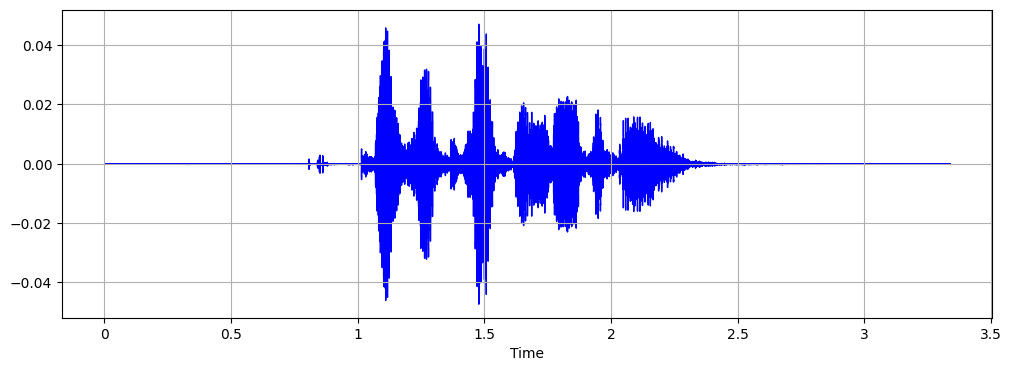

In [14]:
plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio, sr=sampling_rate, color="blue")
plt.grid(True)
plt.show()

In [15]:
X = np.array([np.mean(librosa.feature.mfcc(y=librosa.load(p, res_type='scipy')[0], sr=22050, n_mfcc=40).T, axis=0) for p in df['audio_path']]) #araşdırma
y = df['emotion'].values

print(X.shape)


(8480, 40)


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


In [23]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [24]:
X_train, X_test1, y_train, y_test1 = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)
X_val, X_test, y_val, y_test = train_test_split(
    X_test1, y_test1, test_size=0.5, random_state=42, stratify=y_test1
)
#train validation test setden istifade eledik

In [25]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(5936, 40)
(1272, 40)
(1272, 40)


In [26]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

In [27]:
xgb_model = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)

In [28]:
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [29]:
y_pred = xgb_model.predict(X_test)

In [30]:
accuracy = accuracy_score(y_test, y_pred)

In [31]:
accuracy

0.9512578616352201

In [32]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.96      0.97       178
           1       0.92      0.95      0.93        58
           2       0.95      0.95      0.95       177
           3       0.93      0.97      0.95       177
           4       0.92      0.96      0.94       178
           5       1.00      0.97      0.98       149
           6       0.96      0.92      0.94       177
           7       0.95      0.94      0.95       178

    accuracy                           0.95      1272
   macro avg       0.95      0.95      0.95      1272
weighted avg       0.95      0.95      0.95      1272



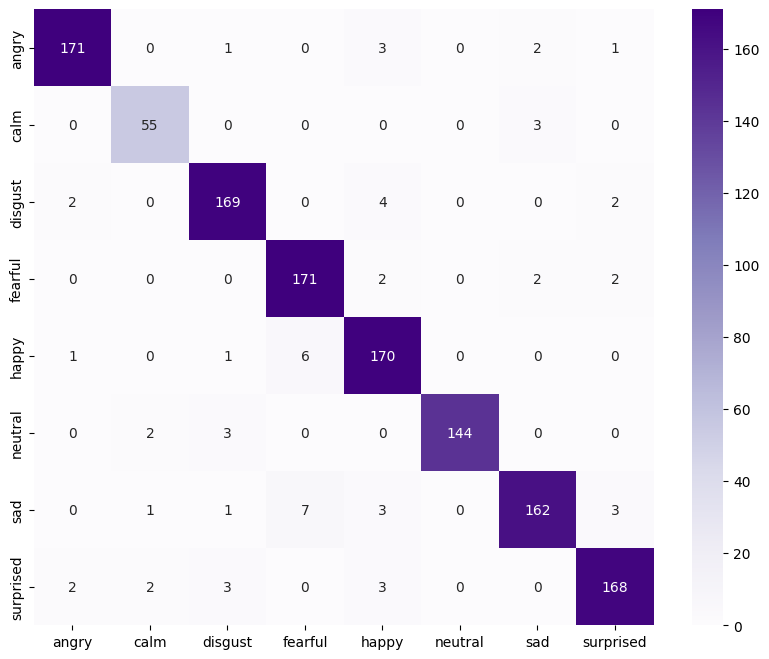

In [33]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.show()

In [34]:
xgb_model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
res = xgb_model.evals_result()

In [35]:
res

{'validation_0': OrderedDict([('mlogloss',
               [1.8003012153578575,
                1.6210303051331936,
                1.476269598096368,
                1.354393773945676,
                1.2506776546150686,
                1.1631235890893763,
                1.0834532684051605,
                1.0120268244085446,
                0.9476594988286816,
                0.8887215404095997,
                0.8365155054191052,
                0.7883432654919972,
                0.7460877135988435,
                0.7076422655528205,
                0.6701592228141917,
                0.6378405945792273,
                0.607572845168251,
                0.5784280312114528,
                0.5523199989457899,
                0.5251416877148085,
                0.5010644533116662,
                0.47945606007649894,
                0.45725605824856824,
                0.43836433342921566,
                0.4200265632347377,
                0.4038545839071796,
                0.387

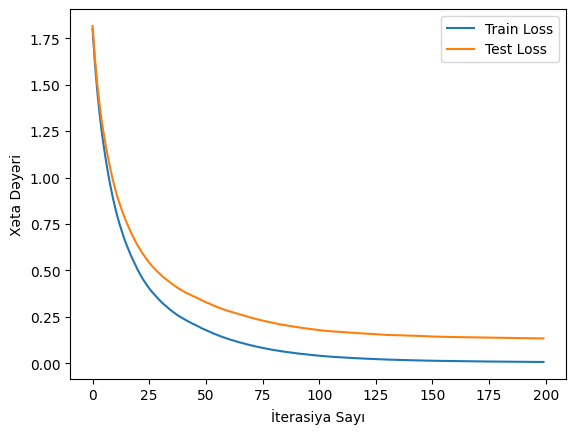

In [36]:
plt.plot(res['validation_0']['mlogloss'], label='Train Loss')
plt.plot(res['validation_1']['mlogloss'], label='Test Loss')

plt.xlabel('İterasiya Sayı') 
plt.ylabel('Xəta Dəyəri')    

plt.legend()
plt.show()

In [37]:
from sklearn.model_selection import GridSearchCV
import xgboost as xgb

In [38]:
param_grid = {
    'n_estimators': [100, 200],      
    'max_depth': [3, 5, 7],          
    'learning_rate': [0.01, 0.1]   
}

In [39]:
xgb_base = xgb.XGBClassifier(eval_metric='mlogloss', random_state=42)


In [40]:
grid_xgb = GridSearchCV(estimator=xgb_base, 
                        param_grid=param_grid, 
                        cv=3, 
                        scoring='accuracy', 
                        verbose=1)

In [41]:
grid_xgb.fit(X_train, y_train)


Fitting 3 folds for each of 12 candidates, totalling 36 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.1], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 

In [42]:
grid_xgb.best_params_

{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}

In [43]:
grid_xgb.best_score_

np.float64(0.9282349230451933)

In [44]:
best_xgb = grid_xgb.best_estimator_

In [45]:
best_xgb.score(X_val, y_val)  # validation accuracy - model seçimi üçün

0.9536163522012578

In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [48]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [49]:
rf_pred = rf_model.predict(X_test)

In [50]:
rf_acc = accuracy_score(y_test, rf_pred)

In [51]:
rf_acc

0.9544025157232704

In [52]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.97      0.96      0.96       178
           1       0.84      0.97      0.90        58
           2       0.95      0.99      0.97       177
           3       0.93      0.96      0.95       177
           4       0.97      0.97      0.97       178
           5       1.00      0.96      0.98       149
           6       0.95      0.90      0.92       177
           7       0.97      0.94      0.95       178

    accuracy                           0.95      1272
   macro avg       0.95      0.96      0.95      1272
weighted avg       0.96      0.95      0.95      1272



In [53]:
from sklearn.model_selection import GridSearchCV

In [54]:
param_grid = {
    'n_estimators': [50, 100, 150],  
    'max_depth': [10, 20 ,30 ]      
}

In [55]:
grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=42), 
                           param_grid=param_grid, 
                           cv=3, 
                           scoring='accuracy',
                           verbose=1)

In [56]:
grid_search.fit(X_train, y_train)


Fitting 3 folds for each of 9 candidates, totalling 27 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displa

In [57]:
grid_search.best_params_

{'max_depth': 30, 'n_estimators': 150}

In [58]:
grid_search.best_score_

np.float64(0.9280650401851732)

In [59]:
best_rf=grid_search.best_estimator_

In [60]:
best_rf.score(X_val, y_val)  # validation accuracy - model seçimi üçün

0.960691823899371

In [61]:
grid_search.predict(X_val)

array([4, 6, 6, ..., 4, 2, 2], shape=(1272,))

In [62]:
cm = confusion_matrix(y_val, grid_search.predict(X_val))


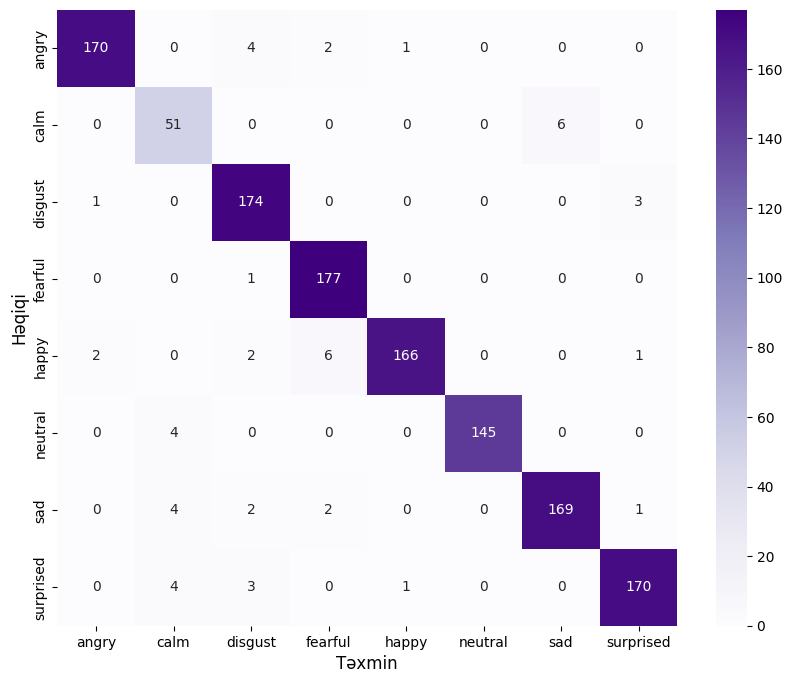

In [63]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Təxmin', fontsize=12)
plt.ylabel('Həqiqi', fontsize=12)
plt.show()

In [64]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [65]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [66]:
svm_scaled_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)

In [67]:
svm_scaled_model.fit(X_train_scaled, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [68]:
svm_scaled_pred = svm_scaled_model.predict(X_val_scaled)


In [69]:
svm_scaled_acc = accuracy_score(y_val, svm_scaled_pred)


In [70]:
svm_scaled_acc

0.8687106918238994

In [71]:
print(classification_report(y_val, svm_scaled_pred))

              precision    recall  f1-score   support

           0       0.95      0.94      0.95       177
           1       0.52      0.86      0.65        57
           2       0.82      0.89      0.85       178
           3       0.89      0.93      0.91       178
           4       0.91      0.79      0.84       177
           5       0.99      0.83      0.91       149
           6       0.86      0.82      0.84       178
           7       0.89      0.88      0.88       178

    accuracy                           0.87      1272
   macro avg       0.85      0.87      0.85      1272
weighted avg       0.88      0.87      0.87      1272



In [72]:
param_grid_svm = {
    'C': [0.1, 1, 10],               
    'gamma': ['scale', 'auto', 0.1], 
    'kernel': ['rbf']              
}


In [73]:
grid_svm_scaled = GridSearchCV(estimator=SVC(probability=True, random_state=42), 
                               param_grid=param_grid_svm, 
                               cv=3, 
                               scoring='accuracy', 
                               verbose=1)

In [74]:
grid_svm_scaled.fit(X_train_scaled, y_train)

Fitting 3 folds for each of 9 candidates, totalling 27 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(probabili...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto', ...], 'kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is

In [75]:
best_svm_scaled=grid_svm_scaled.best_estimator_


In [76]:
svm_scaled_tuned_pred=best_svm_scaled.predict(X_val_scaled)


In [77]:
svm_acc=accuracy_score(y_val, svm_scaled_tuned_pred)


In [78]:
svm_acc

0.9716981132075472

In [79]:
cm_svm_scaled = confusion_matrix(y_val, svm_scaled_tuned_pred)

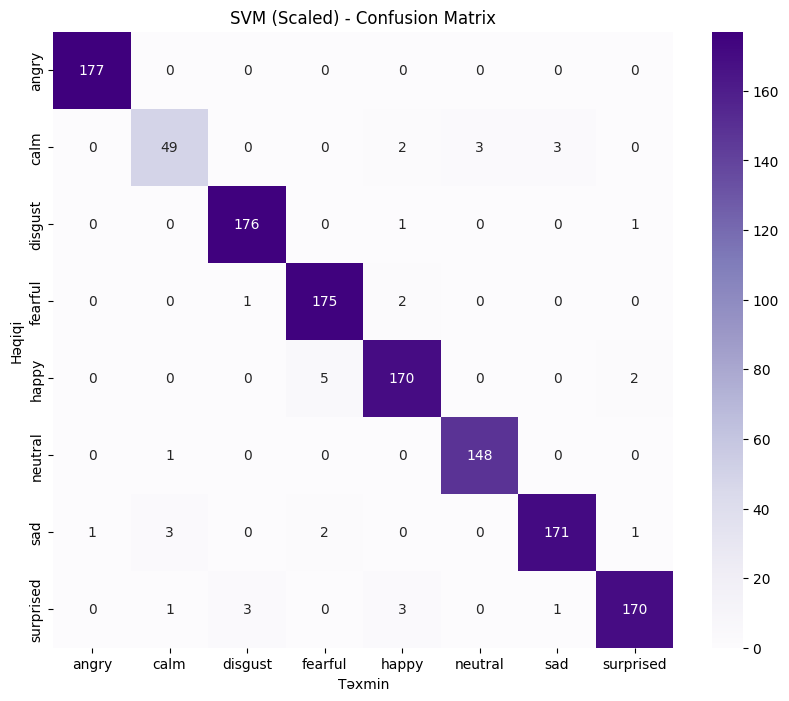

In [80]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm_svm_scaled, annot=True, fmt='d', cmap='Purples', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Təxmin')
plt.ylabel('Həqiqi')
plt.title('SVM (Scaled) - Confusion Matrix')
plt.show()

In [81]:
from sklearn.decomposition import PCA

In [82]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_train)

In [83]:
pca_df = pd.DataFrame(data=pca_result, columns=['PCA1','PCA2'])


In [84]:
pca_df['Emosiya'] = le.inverse_transform(y_train) #biz rəqəmlərə çevirmişdik emosiyalari indi də tərsinə rəqəmləri adına çeviririk

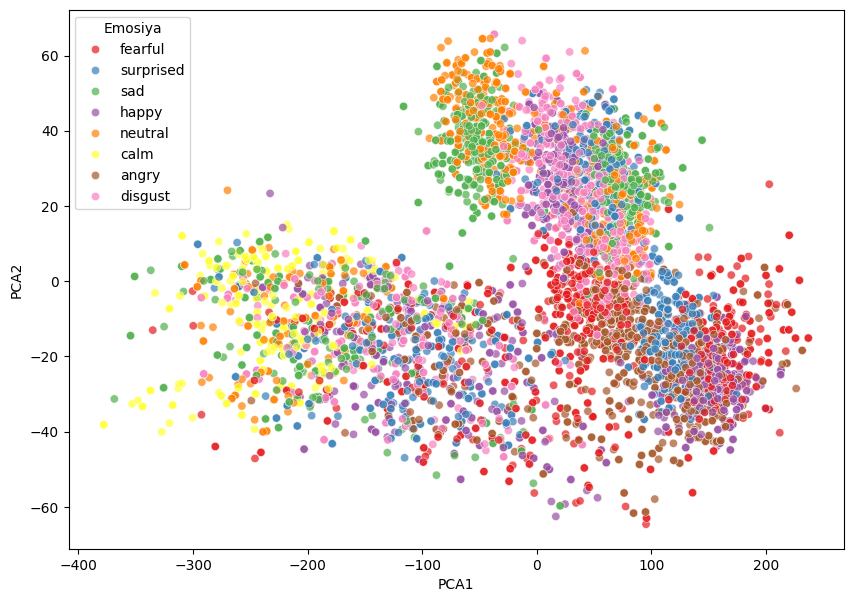

In [85]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x='PCA1', y='PCA2', hue='Emosiya', data=pca_df, palette='Set1', alpha=0.7)
plt.show()

In [86]:
xgb_train, xgb_val = best_xgb.score(X_train, y_train), best_xgb.score(X_val, y_val)
rf_train, rf_val = grid_search.best_estimator_.score(X_train, y_train), grid_search.score(X_val, y_val)
svm_train, svm_val = best_svm_scaled.score(X_train_scaled, y_train), svm_acc

In [87]:
results = pd.DataFrame({
    'Model': ['XGBoost', 'Random Forest', 'SVM (scaled)'],
    'Grid Search-siz (Val)': [accuracy, rf_acc, svm_scaled_acc],
    'Grid Search-lə (Val)': [
        best_xgb.score(X_val, y_val),
        grid_search.score(X_val, y_val),
        svm_acc
    ],
    'Train Accuracy': [xgb_train, rf_train, svm_train],
    'Validation Accuracy': [xgb_val, rf_val, svm_val],
})

results['Train-Val'] = results['Train Accuracy'] - results['Validation Accuracy']
results = results.sort_values('Grid Search-lə (Val)', ascending=False).reset_index(drop=True)
results

,Model,Grid Search-siz (Val),Grid Search-lə (Val),Train Accuracy,Validation Accuracy,Train-Val
0,SVM (scaled),0.868711,0.971698,1.0,0.971698,0.028302
1,Random Forest,0.954403,0.960692,1.0,0.960692,0.039308
2,XGBoost,0.951258,0.953616,1.0,0.953616,0.046384


Train və Validation accuracy arasındakı fərq bütün modellərdə kiçikdir
Deməli modellər overfitting eləmiyib
Model seçimi validation set üzərində aparılıb - Ən yüksək və ən yaxşı nəticəni SVM modeli verib, ona görə də yekun model kimi bunu seçərdim

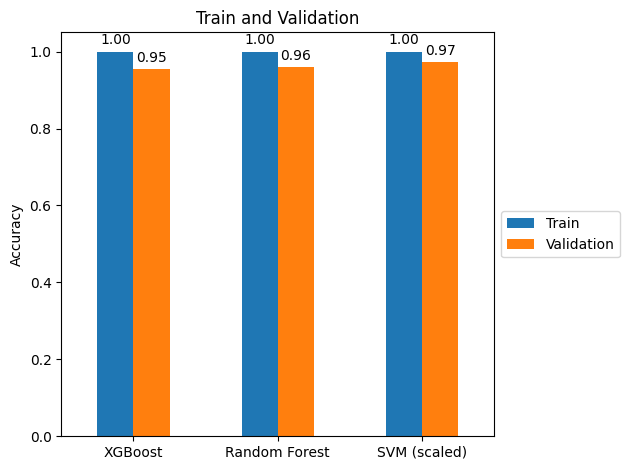

In [88]:
models = ['XGBoost', 'Random Forest', 'SVM (scaled)']
train_scores = [xgb_train, rf_train, svm_train]
val_scores = [xgb_val, rf_val, svm_val]

df_plot = pd.DataFrame({'Train': train_scores, 'Validation': val_scores}, index=models)
ax = df_plot.plot(kind='bar', title='Train and Validation')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.xticks(rotation=0)
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

In [89]:
import opensmile
import random

In [90]:

smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals,
)


In [91]:
random.seed(42) #evvelce mohurledik ki her defe yeni netice alinmasin

pairs = list(zip(file_paths, emotions)) #file ve emotion cutluyumuz 
sampled = random.sample(pairs, 5000)   #cutlukden 5000 dene random sample goturur

In [92]:
sampled_files = [p[0] for p in sampled]      #0-ci indeksimiz bizim faylımızdı
sampled_emotions = [p[1] for p in sampled]   #1-ci indeksimiz də emotionumuzdu


In [93]:
X_opensmile = smile.process_files(sampled_files)
X_opensmile['emotion'] = sampled_emotions

X_opensmile.head()

,,,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,F0semitoneFrom27.5Hz_sma3nz_percentile80.0,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope,F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope,...,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp,emotion
file,start,end,,,,,,,,,,,,,,,,,,,,,
RAVDESS Emotional Speech Audio\audio_speech_actors_01-24\Actor_07\03-01-04-02-01-01-07.wav,0 days,0 days 00:00:03.937250,28.978456,0.196150,26.500372,29.954906,34.147011,7.646639,426.950287,651.705933,56.707409,110.021942,...,0.007724,0.013648,2.551021,1.550388,0.236667,0.111156,0.378333,0.439561,-44.331585,sad
RAVDESS Emotional Speech Audio\Actor_07\03-01-07-02-01-02-07.wav,0 days,0 days 00:00:04.404395833,26.411245,0.149074,22.588154,26.573479,30.278385,7.690231,51.268433,24.228281,40.199310,28.198452,...,0.003512,0.030001,2.050114,1.612903,0.235714,0.095148,0.317500,0.389029,-41.244034,disgust
TESS Kaggle dataset\TESS Toronto emotional speech set data\TESS Toronto emotional speech set data\OAF_disgust\OAF_date_disgust.wav,0 days,0 days 00:00:02.535635290,32.755550,0.118629,30.988754,33.050941,35.074150,4.085396,102.741043,128.517166,26.287033,78.780472,...,-0.006531,0.042369,2.380952,1.214575,0.530000,0.461086,0.202500,0.134977,-31.806273,disgust
TESS Kaggle dataset\TESS Toronto emotional speech set data\OAF_Pleasant_surprise\OAF_rat_ps.wav,0 days,0 days 00:00:01.840747112,35.946766,0.137689,32.167255,33.747009,38.688797,6.521542,36.669170,24.358976,73.737999,35.350243,...,-0.006591,0.071188,3.278689,0.561798,1.380000,0.000000,0.185000,0.025000,-30.826677,surprised
TESS Kaggle dataset\TESS Toronto emotional speech set data\OAF_happy\OAF_tool_happy.wav,0 days,0 days 00:00:01.825591874,37.793320,0.149174,32.839615,36.846611,43.491306,10.651691,57.340710,33.361641,72.638710,23.574553,...,-0.004374,0.039609,2.762431,1.714286,0.416667,0.097411,0.146667,0.089567,-31.767664,happy


İndi bunu neyron network üzərində tətbiq edək

In [94]:
from sklearn.preprocessing import normalize
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow.keras.layers import LSTM, Dense, Dropout ,GRU
from tensorflow import keras
from keras.callbacks import History, ReduceLROnPlateau
from tensorflow.keras.optimizers import SGD, Adam, RMSprop
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import Sequential
from keras.activations import *

In [95]:
X = X_opensmile.drop("emotion", axis=1)
y = X_opensmile["emotion"]

In [96]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [97]:
x_train, x_temp, y_train, y_temp = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)


In [98]:
y_train = to_categorical(y_train)
y_val = to_categorical(y_val)
y_test = to_categorical(y_test)

In [99]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [100]:
from tensorflow.keras.layers import BatchNormalization

model = Sequential()
model.add(Dense(256, activation="relu", input_shape=(x_train.shape[1],)))
model.add(BatchNormalization())
model.add(Dropout(0.3))
model.add(Dense(128, activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.3))
model.add(Dense(64, activation="relu"))
model.add(Dense(len(le.classes_), activation="softmax"))

In [101]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │          22,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 8)                   │             520 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 65,992 (257.78 KB)

 Trainable params: 65,224 (254.78 KB)

 Non-trainable params: 768 (3.00 KB)

In [102]:
adam = Adam(learning_rate=0.001)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
model.compile(optimizer=adam, loss="categorical_crossentropy", metrics=["categorical_accuracy"])

In [103]:
history = History()
early = tf.keras.callbacks.EarlyStopping(monitor='val_categorical_accuracy', patience=10, restore_best_weights=True)

In [104]:
model.fit(x_train, y_train, epochs=150, validation_data=(x_val, y_val), 
          callbacks=[history, early, reduce_lr], batch_size=32)

Epoch 1/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - categorical_accuracy: 0.5889 - loss: 1.1775 - val_categorical_accuracy: 0.7467 - val_loss: 0.8246 - learning_rate: 0.0010
Epoch 2/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - categorical_accuracy: 0.7557 - loss: 0.7095 - val_categorical_accuracy: 0.7853 - val_loss: 0.6039 - learning_rate: 0.0010
Epoch 3/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - categorical_accuracy: 0.7760 - loss: 0.6184 - val_categorical_accuracy: 0.7973 - val_loss: 0.5431 - learning_rate: 0.0010
Epoch 4/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - categorical_accuracy: 0.8066 - loss: 0.5340 - val_categorical_accuracy: 0.8067 - val_loss: 0.5266 - learning_rate: 0.0010
Epoch 5/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - categorical_accuracy: 0.8183 - loss: 0.5063 - val_categorical_accuracy: 0.8093 - val_loss: 0.5007 - learning_rate: 0.0010
Epoch 6/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - categorical_accuracy: 0.8340 - loss: 0.4749 - val_categoric

Canlı Demo əlavə eliyək-Araşdırma nəticəsi

In [105]:
import sounddevice as sd
import soundfile as sf
from IPython.display import Audio

In [106]:
print(librosa.get_samplerate(file_paths[0])) #bizim seslerin tezliyine baxiriq

48000


In [107]:
def extract_mfcc_features(file_path):
    audio, sr = librosa.load(file_path, res_type='scipy')
    mfcc = librosa.feature.mfcc(y=audio, sr=22050, n_mfcc=40)
    return np.mean(mfcc.T, axis=0)


In [108]:
X_mfcc_all = np.array([extract_mfcc_features(f) for f in file_paths])
y_mfcc_all = le.transform(emotions)


In [109]:
X_train_mfcc, X_test_mfcc, y_train_mfcc, y_test_mfcc = train_test_split(
    X_mfcc_all, y_mfcc_all, test_size=0.2, random_state=42, stratify=y_mfcc_all
)


In [110]:
scaler_svm = StandardScaler()
X_train_mfcc_scaled = scaler_svm.fit_transform(X_train_mfcc)
X_test_mfcc_scaled = scaler_svm.transform(X_test_mfcc)

In [116]:
fs = 48000
duration = 5

print("Danışmağa başla...")
recording = sd.rec(int(duration * fs), samplerate=fs, channels=1)
sd.wait()
sf.write("my_voice.wav", recording, fs)
print("Yazı bitdi")

Audio("my_voice.wav")

Danışmağa başla...
Yazı bitdi


In [117]:
from sklearn.svm import SVC

final_demo_svm = SVC(**best_svm_scaled.get_params())
final_demo_svm.fit(X_train_mfcc_scaled, y_train_mfcc)

print("Yeni test accuracy:", final_demo_svm.score(X_test_mfcc_scaled, y_test_mfcc))

Yeni test accuracy: 0.9787735849056604


In [118]:
my_features = extract_mfcc_features("my_voice.wav").reshape(1, -1)
my_features_scaled = scaler_svm.transform(my_features)

prediction = final_demo_svm.predict(my_features_scaled)
predicted_emotion = le.inverse_transform(prediction)

print("Model-in təxmini:", predicted_emotion[0])


Model-in təxmini: fearful
